In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:

df = pd.read_csv("netflix_titles.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [3]:

print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nStatistical Summary:")
print(df.describe(include="all"))

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB

Missing Values:
show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
list

In [4]:

print("Missing values before cleaning:")
print(df.isnull().sum())


print("\nDuplicate rows:", df.duplicated().sum())

Missing values before cleaning:
show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

Duplicate rows: 0


In [5]:

df_clean = df.copy()


df_clean = df_clean.drop_duplicates()

df_clean["director"] = df_clean["director"].fillna("Unknown")
df_clean["cast"] = df_clean["cast"].fillna("Unknown")
df_clean["country"] = df_clean["country"].fillna("Unknown")
df_clean["rating"] = df_clean["rating"].fillna("Not Rated")
df_clean["duration"] = df_clean["duration"].fillna("Unknown")


print("Missing values after cleaning:")
print(df_clean.isnull().sum())

print("\nCleaned dataset shape:", df_clean.shape)

Missing values after cleaning:
show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      10
release_year     0
rating           0
duration         0
listed_in        0
description      0
dtype: int64

Cleaned dataset shape: (8807, 12)


In [6]:

df_clean.to_csv("netflix_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


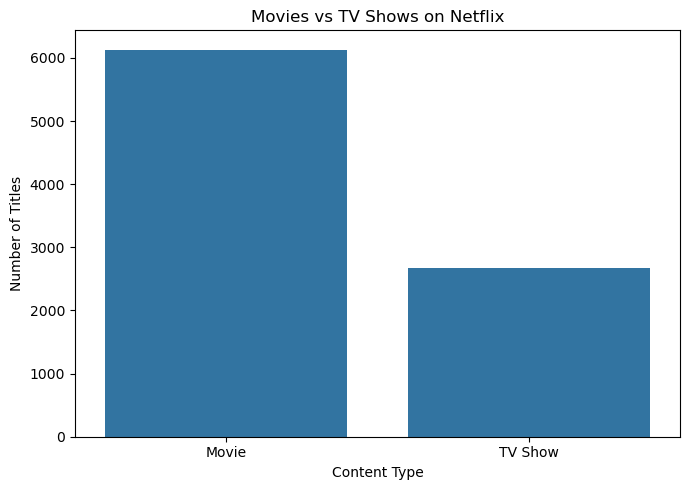

In [7]:

plt.figure(figsize=(7, 5))

sns.countplot(data=df_clean, x="type")

plt.title("Movies vs TV Shows on Netflix")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")

plt.tight_layout()
plt.show()

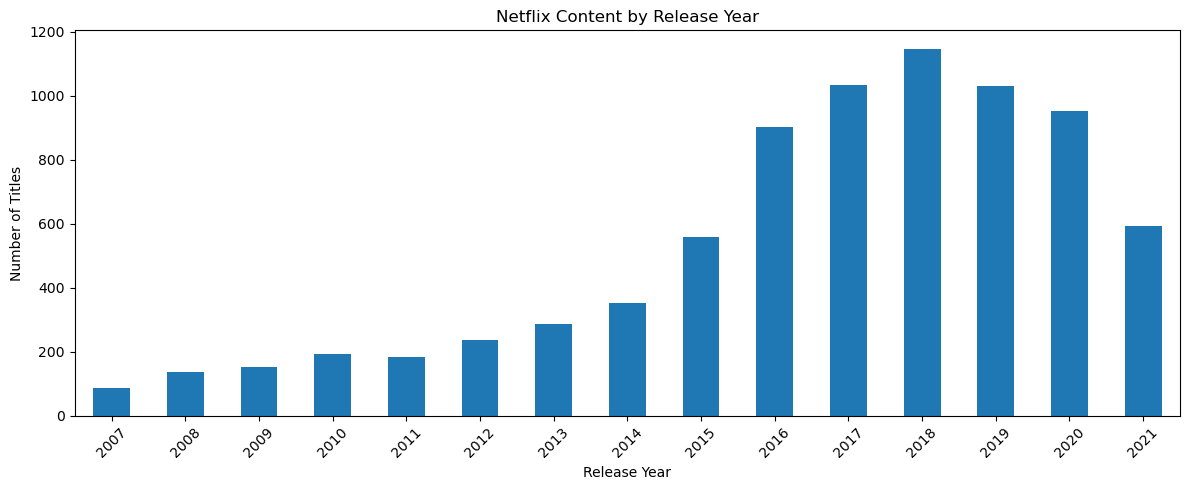

In [8]:

# Top 15 release years
year_counts = df_clean["release_year"].value_counts().sort_index()

plt.figure(figsize=(12, 5))
year_counts.tail(15).plot(kind="bar")

plt.title("Netflix Content by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

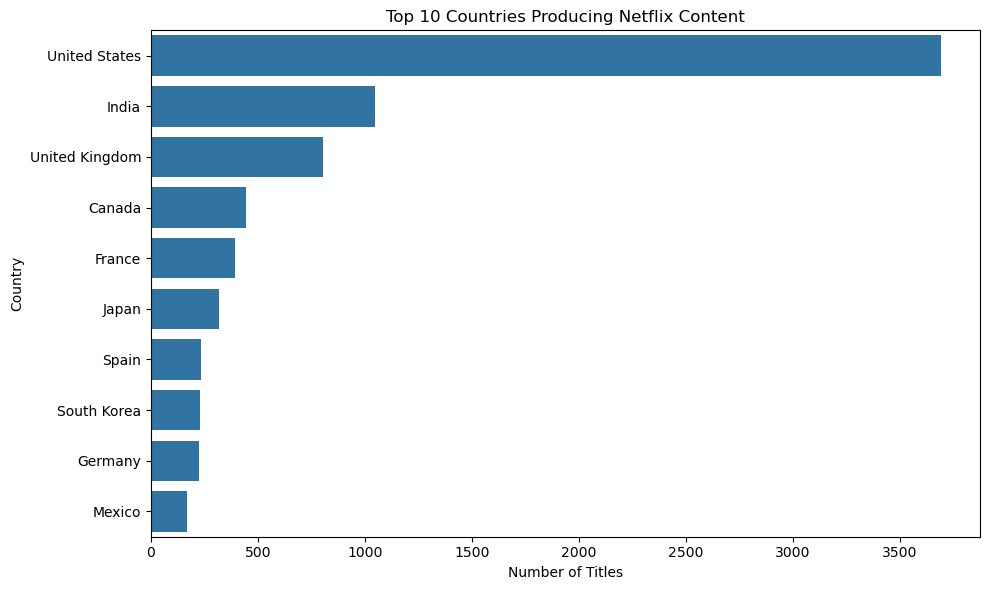

In [9]:

country_counts = (
    df_clean[df_clean["country"] != "Unknown"]["country"]
    .str.split(", ")
    .explode()
    .value_counts()
    .head(10)
)

plt.figure(figsize=(10, 6))
sns.barplot(x=country_counts.values, y=country_counts.index)

plt.title("Top 10 Countries Producing Netflix Content")
plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

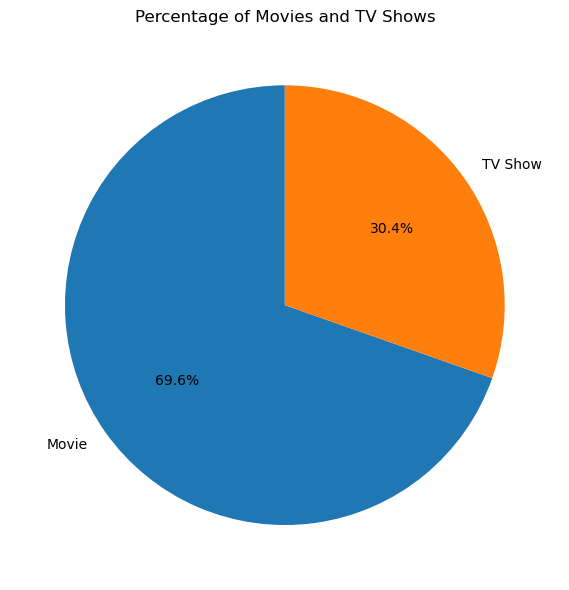

In [10]:

type_counts = df_clean["type"].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(
    type_counts.values,
    labels=type_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Percentage of Movies and TV Shows")
plt.tight_layout()
plt.show()

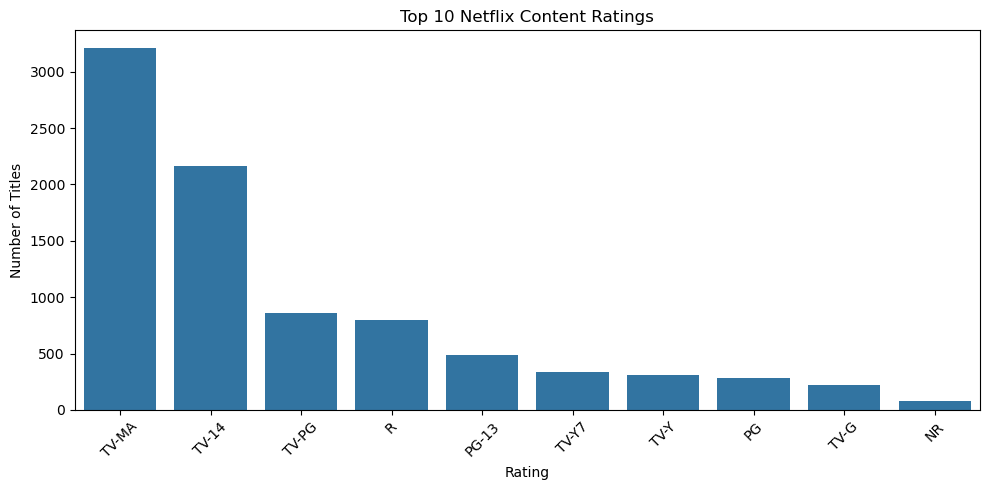

In [11]:

rating_counts = df_clean["rating"].value_counts().head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=rating_counts.index, y=rating_counts.values)

plt.title("Top 10 Netflix Content Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

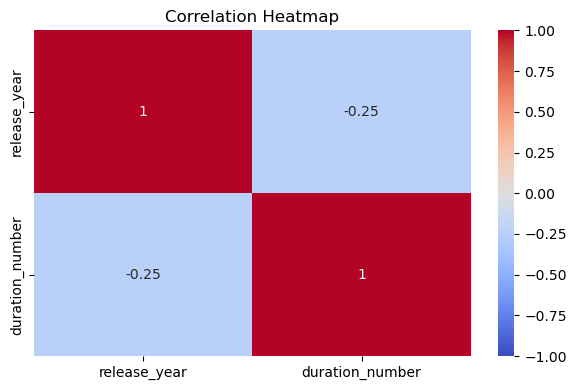

In [12]:

corr_df = pd.DataFrame({
    "release_year": pd.to_numeric(
        df_clean["release_year"], errors="coerce"
    ),
    "duration_number": pd.to_numeric(
        df_clean["duration"].str.extract(r"(\d+)")[0],
        errors="coerce"
    )
})

plt.figure(figsize=(6, 4))
sns.heatmap(
    corr_df.corr(),
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [13]:

print("========== NETFLIX EDA SUMMARY ==========")
print("Total Titles:", len(df_clean))
print("Total Columns:", df_clean.shape[1])
print("Movies:", (df_clean["type"] == "Movie").sum())
print("TV Shows:", (df_clean["type"] == "TV Show").sum())
print("Unique Release Years:", df_clean["release_year"].nunique())
print("Top 5 Ratings:")
print(df_clean["rating"].value_counts().head())
print("=========================================")

========== NETFLIX EDA SUMMARY ==========
Total Titles: 8807
Total Columns: 12
Movies: 6131
TV Shows: 2676
Unique Release Years: 74
Top 5 Ratings:
rating
TV-MA    3207
TV-14    2160
TV-PG     863
R         799
PG-13     490
Name: count, dtype: int64


In [14]:

print("========== FINAL FINDINGS ==========")

print("Total titles:", len(df_clean))
print("\nContent type distribution:")
print(df_clean["type"].value_counts())

print("\nMost common release years:")
print(df_clean["release_year"].value_counts().head(5))

print("\nTop 5 countries:")
print(
    df_clean[df_clean["country"] != "Unknown"]["country"]
    .str.split(", ")
    .explode()
    .value_counts()
    .head(5)
)

print("\nTop 5 ratings:")
print(df_clean["rating"].value_counts().head(5))

print("\nFinal missing values:")
print(df_clean.isnull().sum())

========== FINAL FINDINGS ==========
Total titles: 8807

Content type distribution:
type
Movie      6131
TV Show    2676
Name: count, dtype: int64

Most common release years:
release_year
2018    1147
2017    1032
2019    1030
2020     953
2016     902
Name: count, dtype: int64

Top 5 countries:
country
United States     3689
India             1046
United Kingdom     804
Canada             445
France             393
Name: count, dtype: int64

Top 5 ratings:
rating
TV-MA    3207
TV-14    2160
TV-PG     863
R         799
PG-13     490
Name: count, dtype: int64

Final missing values:
show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      10
release_year     0
rating           0
duration         0
listed_in        0
description      0
dtype: int64


In [15]:
df_clean.to_csv("netflix_cleaned.csv", index=False)

In [16]:
import os
print(os.getcwd())
print(os.path.exists("netflix_cleaned.csv"))

C:\Users\Jenima
True


In [17]:
df_clean.to_csv("netflix_cleaned.csv", index=False)

In [18]:
import os
print(os.getcwd())
print(os.path.exists("netflix_cleaned.csv"))

C:\Users\Jenima
True


In [19]:
df_clean.to_csv("netflix_cleaned.csv", index=False)

In [20]:

import os
print(os.getcwd())
print(os.path.exists("netflix_cleaned.csv"))


C:\Users\Jenima
True


In [21]:
import pandas as pd

df = pd.read_csv("netflix_titles.csv")

df_clean = df.drop_duplicates().copy()

for col in ["director", "cast", "country", "rating", "duration"]:
    df_clean[col] = df_clean[col].fillna("Unknown")

df_clean.to_csv("netflix_cleaned.csv", index=False)

print("Cleaned CSV created successfully!")
print(df_clean.shape)

Cleaned CSV created successfully!
(8807, 12)


In [22]:
import os

os.chdir(r"C:\Users\Jenima\Desktop\Netflix_EDA_Project")
print(os.getcwd())

C:\Users\Jenima\Desktop\Netflix_EDA_Project


In [23]:
import pandas as pd

df = pd.read_csv("netflix_titles.csv")
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [24]:
import os

print("Current folder:", os.getcwd())
print("Files in this folder:")
print(os.listdir())

Current folder: C:\Users\Jenima\Desktop\Netflix_EDA_Project
Files in this folder:
['app.py', 'netflix_titles.csv']


In [25]:
import pandas as pd

df = pd.read_csv("netflix_titles.csv")

df_clean = df.drop_duplicates().copy()

for col in ["director", "cast", "country", "rating", "duration"]:
    df_clean[col] = df_clean[col].fillna("Unknown")

df_clean.to_csv("netflix_cleaned.csv", index=False)

print("Cleaned CSV created successfully!")
print("Files:", __import__("os").listdir())

Cleaned CSV created successfully!
Files: ['app.py', 'netflix_cleaned.csv', 'netflix_titles.csv']
